# Laboratorium 4: Transformer jako model

W poprzednich laboratoriach pracowaliśmy z TF-IDF i gotowymi embeddingami. W tym laboratorium przechodzimy do modelu transformerowego używanego bezpośrednio jako klasyfikator.

Śledzimy cały przepływ:

`tekst → tokenizator → input_ids + attention_mask → enkoder → reprezentacja → głowa klasyfikacyjna → logity → predykcja`

Główne pytanie laboratorium brzmi:

**Co daje dostrajanie transformera i kiedy wzrost jakości uzasadnia dodatkowy koszt względem prostszego baseline'u?**

Porównamy:

- `TF-IDF + Linear SVM` z laboratorium 2;
- transformer z zamrożonym enkoderem;
- ten sam transformer po pełnym dostrojeniu.

Laboratorium obejmuje 10 zadań obowiązkowych i jedno opcjonalne.

## Po tych zajęciach student potrafi

- wyjaśnić różnicę między słowem, tokenem i subwordem;
- odczytać `input_ids` i `attention_mask`;
- wyjaśnić rolę paddingu i obcinania sekwencji;
- odczytać podstawowe informacje o architekturze modelu;
- wykonać przejście w przód bez użycia `pipeline()`;
- zinterpretować `last_hidden_state`, logity i wynik softmax;
- przygotować dane do klasyfikacji tekstu transformerem;
- porównać zamrożony enkoder z pełnym dostrajaniem;
- porównać transformera z klasycznym baseline'em;
- porównać model wielojęzyczny z polskim pod względem tokenizacji, jakości i kosztu (opcjonalnie);
- przeprowadzić analizę błędów i uzasadnić decyzję projektową.

## Dane i protokół

Pracujemy na tym samym zbiorze PolEmo 2.0 co w laboratoriach 1-3.

Obowiązuje ten sam protokół:

- `train` -- uczenie;
- `validation` -- porównywanie wariantów i wybór konfiguracji;
- `test` -- jedna końcowa ocena wybranego rozwiązania.

Wynik `TF-IDF + Linear SVM` z laboratorium 2 jest punktem odniesienia. Nie zmieniamy baseline'u po zobaczeniu wyników transformera.

Jeżeli ograniczenia sprzętowe wymagają zmniejszenia liczby przykładów treningowych, należy ustawić TRAIN_LIMIT (np. 2000, próbka stratyfikowana, ta sama we wszystkich eksperymentach transformerowych) i opisać to w karcie modelu.

## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow torch transformers datasets accelerate
```

Model używany w laboratorium:

```text
distilbert/distilbert-base-multilingual-cased
```

W Zadaniu 8 (opcjonalnie): `allegro/herbert-base-cased`, model wstępnie wytrenowany na korpusach polskich.


Kod startowy obejmuje importy, stałe i wczytanie danych. Implementacja właściwych eksperymentów należy do Państwa.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import re

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)

RANDOM_STATE = 42
set_seed(RANDOM_STATE)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"
# MODEL_PL = "allegro/herbert-base-cased"   # zadanie 8 (opcjonalnie)
MAX_LENGTH = 128        # zadanie 2
TRAIN_LIMIT = 2000      # None = cały train; na CPU proponowane 2000

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None)
    and torch.backends.mps.is_available()
    else "cpu"
)

print("Urządzenie:", DEVICE)

c:\Users\zsuet\Desktop\nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Urządzenie: cpu


In [2]:
# helpery z labu 2 (bootstrap_ci, macro_f1) + nowe: paired_bootstrap_diff, token_stats

from sklearn.metrics import f1_score

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)
    
def paired_bootstrap_diff(y_true, pred_a, pred_b, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(metric(y_true[i], pred_b[i]) - metric(y_true[i], pred_a[i]))
    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, pred_b) - metric(y_true, pred_a)), float(lo), float(hi)

def token_stats(tokenizer, texts, max_length):
    texts = list(texts)
    ids = tokenizer(texts, add_special_tokens=True, truncation=False)["input_ids"]
    lens = np.array([len(x) for x in ids])
    n_words = np.array([len(re.findall(r"\w+", t)) for t in texts])
    return {
        "median": float(np.median(lens)),
        "p90": float(np.percentile(lens, 90)),
        "pct_truncated": float((lens > max_length).mean()),
        "tokens_per_word": float(lens.sum() / n_words.sum()),
    }

In [3]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"].isin(["validation", "valid"])].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

if TRAIN_LIMIT is not None:
    train_df, _ = train_test_split(
        train_df, train_size=TRAIN_LIMIT, stratify=train_df["target"], random_state=RANDOM_STATE
    )
    train_df = train_df.reset_index(drop=True)

CLASSES = sorted(train_df["target"].unique())
print("train:", len(train_df), "validation:", len(val_df), "test:", len(test_df))

train: 2000 validation: 723 test: 722


# Zadanie 1: Audyt tokenizacji

Proszę wczytać tokenizator `MODEL_NAME` i przygotować co najmniej 8 polskich przykładów obejmujących wybrane zróżnicowane zjawiska z podanej poniżej listy:

- częste słowo;
- rzadkie słowo;
- nazwę własną;
- nazwisko;
- wyraz z polskimi znakami;
- ten sam wyraz bez polskich znaków;
- literówkę;
- neologizm;
- emoji;
- URL;
- liczbę;
- termin specjalistyczny.

Dla każdego przykładu proszę zapisać:

| tekst | liczba słów | liczba tokenów | tokeny | obserwacja |
|---|---:|---:|---|---|

Proszę krótko odpowiedzieć:

1. Czy token odpowiada słowu?
2. Jak tokenizator zachowuje się wobec nietypowych form?
3. Dlaczego tokenizacja może wpływać na późniejszy wynik modelu?

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

type(tokenizer).__name__

'BertTokenizer'

In [5]:
examples = {
    "Częste słowo": "Jest bardzo dobrze",
    "Rzadkie słowo": "Ale z ciebie huncwot",
    "Nazwa własna": "Jedziemy nad Morze Bałtyckie",
    "Nazwisko": "Henryk Sienkiewicz był wybitnym pisarzem",
    "Wyraz z polskimi znakami": "Żółć",
    "Wyraz bez polskich znaków": "Zolc",
    "Literówka": "Nie przeasdzaj",
    "Literówka bez literówki": "Nie przesadzaj",
    "Neologizm": "Widać, że jesteś ogarnięty",
    "Emoji": "Super 🔥🔥🔥🔥🔥🔥🔥",
    "URL": "Uważaj na niebezpieczne linki, takie jak: https://guthib.com/",
    "Liczba": "Bardzo znana bitwa odbyła się w 1410 roku",
    "Termin specjalistyczny": "Pacjent przebywa na oddziale kardiochirurgii"
}

In [6]:
observations = {
    "Częste słowo": "Każde słowo to jeden token.",
    "Rzadkie słowo": "`huncwot` rozpadło się na 4 fragmenty (hun ##c ##wo ##t).",
    "Nazwa własna": "`Bałtyckie` pocięte na 4 fragmenty bez znaczenia (Ba ##ł ##ty ##ckie).",
    "Nazwisko": "`Sienkiewicz` to tylko 2 tokeny (Sien ##kiewicz).",
    "Wyraz z polskimi znakami": "1 słowo to 3 tokeny (Ż ##ół ##ć).",
    "Wyraz bez polskich znaków": "Ten sam wyraz to 2 tokeny (Zo ##lc), czyli inny podział niż z diakrytykami.",
    "Literówka": "`przeasdzaj` podzielone przypadkowo (pr ##zea ##sd ##zaj).",
    "Literówka bez literówki": "Poprawne słowo też rozbite (pr ##zesa ##dza ##j), tyle samo tokenów co z literówką, ale inne fragmenty.",
    "Neologizm": "`ogarnięty` rozbite na 3 fragmenty (og ##arni ##ęty), bez śladu potocznego znaczenia.",
    "Emoji": "7 emoji to jeden `[UNK]`, informacja przepadła.",
    "URL": "Adres to 9 tokenów, głównie znaki interpunkcyjne (https : / / gut ##hib . com /).",
    "Liczba": "`1410` to jeden token.",
    "Termin specjalistyczny": "`kardiochirurgii` rozpadło się na 6 fragmentów (kar ##dio ##chi ##ru ##rgi ##i).",
}

tokenization_results = []

for group, text in examples.items():
    tokens = tokenizer.tokenize(text)
    tokenization_results.append({
        "zjawisko": group,
        "tekst": text,
        "liczba słów": len(re.findall(r"\w+", text)),
        "liczba tokenów": len(tokens),
        "tokeny": tokens,
        "obserwacja": observations[group],
    })
    
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(tokenization_results))


,zjawisko,tekst,liczba słów,liczba tokenów,tokeny,obserwacja
0,Częste słowo,Jest bardzo dobrze,3,3,"[Jest, bardzo, dobrze]",Każde słowo to jeden token.
1,Rzadkie słowo,Ale z ciebie huncwot,4,9,"[Ale, z, ci, ##eb, ##ie, hun, ##c, ##wo, ##t]",`huncwot` rozpadło się na 4 fragmenty (hun ##c ##wo ##t).
2,Nazwa własna,Jedziemy nad Morze Bałtyckie,4,10,"[Je, ##dzie, ##my, nad, Mor, ##ze, Ba, ##ł, ##ty, ##ckie]",`Bałtyckie` pocięte na 4 fragmenty bez znaczenia (Ba ##ł ##ty ##ckie).
3,Nazwisko,Henryk Sienkiewicz był wybitnym pisarzem,5,10,"[Henryk, Sien, ##kiewicz, był, w, ##y, ##bit, ##nym, pisarz, ##em]",`Sienkiewicz` to tylko 2 tokeny (Sien ##kiewicz).
4,Wyraz z polskimi znakami,Żółć,1,3,"[Ż, ##ół, ##ć]",1 słowo to 3 tokeny (Ż ##ół ##ć).
5,Wyraz bez polskich znaków,Zolc,1,2,"[Zo, ##lc]","Ten sam wyraz to 2 tokeny (Zo ##lc), czyli inny podział niż z diakrytykami."
6,Literówka,Nie przeasdzaj,2,5,"[Nie, pr, ##zea, ##sd, ##zaj]",`przeasdzaj` podzielone przypadkowo (pr ##zea ##sd ##zaj).
7,Literówka bez literówki,Nie przesadzaj,2,5,"[Nie, pr, ##zesa, ##dza, ##j]","Poprawne słowo też rozbite (pr ##zesa ##dza ##j), tyle samo tokenów co z literówką, ale inne fragmenty."
8,Neologizm,"Widać, że jesteś ogarnięty",4,10,"[Wi, ##dać, ,, że, jest, ##e, ##ś, og, ##arni, ##ęty]","`ogarnięty` rozbite na 3 fragmenty (og ##arni ##ęty), bez śladu potocznego znaczenia."
9,Emoji,Super 🔥🔥🔥🔥🔥🔥🔥,1,2,"[Super, [UNK]]","7 emoji to jeden `[UNK]`, informacja przepadła."


# Zadanie 2: `input_ids`, `attention_mask`, padding i obcinanie

Proszę wybrać trzy teksty o różnej długości i przygotować je do wejścia modelu.

Dla każdego tekstu proszę wyświetlić:

- tokeny;
- `input_ids`;
- `attention_mask`;
- długość sekwencji.

Następnie proszę porównać `padding=True` oraz `padding="max_length", max_length=128` i policzyć, jaki procent pozycji w batchu stanowi padding.

Następnie proszę sprawdzić długości tokenowe wszystkich tekstów treningowych i podać:

- medianę;
- percentyl 90;
- percentyl 95;
- maksimum;
- procent tekstów obcinanych przy `MAX_LENGTH=128`.

Na tej podstawie proszę zdecydować, czy `128` jest rozsądną wartością dla dalszej części laboratorium (przy obcinaniu znika koniec tekstu, a w recenzjach często jest tam podsumowanie oceny). Decyzję i procent obciętych tekstów proszę zapisać w karcie modelu.

In [7]:
input_texts = {
    "krótki": "Polecam!",
    "średni": "Hotel nawet czysty, obsługa bardzo miła, ale śniadania to mają fatalne.",
    "długi": "Pan doktor ma niesamowity dar jasnowidzenia. Zbadał mnie wzrokiem z odległości trzech metrów, nie wstając z krzesła i nie dotykając stetoskopu. Wizyta trwała krócej niż wpisanie PIN-u do terminala płatniczego. Za taką stawkę minutową pan doktor mógłby spokojnie doradzać na Wall Street. Wyszedłem z informacją, że w moim wieku to już trzeba powoli przyzwyczajać się do ziemi. Doceniam szczerość, choć liczyłem raczej na maść."
}

input_rows = []
for name, text in input_texts.items():
    enc = tokenizer(text)
    input_rows.append({
        "tekst": name,
        "tokeny": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
        "input_ids": enc["input_ids"],
        "attention_mask": enc["attention_mask"],
        "długość sekwencji": len(enc["input_ids"])
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(input_rows))

,tekst,tokeny,input_ids,attention_mask,długość sekwencji
0,krótki,"[[CLS], Pole, ##cam, !, [SEP]]","[101, 37959, 67354, 106, 102]","[1, 1, 1, 1, 1]",5
1,średni,"[[CLS], Hotel, nawet, czy, ##sty, ,, ob, ##s, ##ług, ##a, bardzo, mi, ##ła, ,, ale, ś, ##nia, ##dania, to, mają, fatal, ##ne, ., [SEP]]","[101, 15411, 36633, 22427, 37134, 117, 17339, 10107, 107265, 10113, 24004, 12132, 12294, 117, 11372, 348, 11335, 54276, 10114, 33025, 71126, 10238, 119, 102]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]",24
2,długi,"[[CLS], Pan, doktor, ma, nie, ##sam, ##owi, ##ty, dar, jasno, ##wid, ##zenia, ., Z, ##bada, ##ł, m, ##nie, w, ##z, ##rok, ##iem, z, odległości, trzech, metrów, ,, nie, w, ##sta, ##jąc, z, kr, ##zes, ##ła, i, nie, dot, ##yka, ##jąc, st, ##etos, ##kop, ##u, ., Wi, ##zy, ##ta, tr, ##wała, kr, ##óc, ##ej, niż, w, ##pis, ##anie, P, ##IN, -, u, do, terminal, ##a, p, ##ła, ##tni, ##czego, ., Za, tak, ##ą, sta, ##w, ##kę, minuto, ##wą, pan, doktor, mógł, ##by, sp, ##oko, ##jnie, dor, ##ad, ##zać, na, Wall, Street, ., W, ##ys, ##zed, ##łem, z, informa, ##cją, ,, że, ...]","[101, 18661, 43307, 10824, 11058, 34945, 22578, 11195, 12923, 96500, 109030, 20482, 119, 163, 43342, 11133, 181, 11297, 191, 10305, 41603, 13711, 194, 49957, 31506, 31086, 117, 11058, 191, 10972, 15442, 194, 50302, 19579, 12294, 177, 11058, 81160, 31686, 15442, 28780, 61577, 46392, 10138, 119, 52742, 12547, 10213, 32221, 27453, 50302, 60937, 11950, 28773, 191, 16825, 20461, 153, 27128, 118, 189, 10149, 23552, 10113, 184, 12294, 34431, 49008, 119, 14074, 12741, 10621, 16527, 10874, 18371, 49697, 19195, 24960, 43307, 72296, 11530, 32650, 20954, 74633, 33518, 11488, 91047, 10132, 19523, 11962, 119, 160, 12682, 18309, 31553, 194, 93039, 20717, 117, 12537, ...]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...]",140


In [8]:
batch_texts = list(input_texts.values())

def padding_share(enc):
    mask = np.asarray(enc["attention_mask"])
    return 1 - mask.sum() / mask.size

enc_dynamic = tokenizer(batch_texts, padding=True, truncation=True, max_length=128)
enc_fixed = tokenizer(batch_texts, padding="max_length", truncation=True, max_length=128)

display(pd.DataFrame([
    {"wariant": "padding=True",
     "kształt batcha": np.asarray(enc_dynamic["input_ids"]).shape,
     "% paddingu": round(100 * padding_share(enc_dynamic), 1)},
    {"wariant": 'padding="max_length", max_length=128',
     "kształt batcha": np.asarray(enc_fixed["input_ids"]).shape,
     "% paddingu": round(100 * padding_share(enc_fixed), 1)},
]))

print("input_ids:", enc_dynamic["input_ids"][0])
print("attention_mask:", enc_dynamic["attention_mask"][0])
print("pad_token:", tokenizer.pad_token, "| id:", tokenizer.pad_token_id)

,wariant,kształt batcha,% paddingu
0,padding=True,"(3, 128)",59.1
1,"padding=""max_length"", max_length=128","(3, 128)",59.1


input_ids: [101, 37959, 67354, 106, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
pad_token: [PAD] | id: 0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


,liczba tokenów
mediana,222.0
p90,420.0
p95,524.1
maksimum,1353.0
% obciętych przy 128,83.6


,max_length,% obciętych
0,128,83.6
1,256,35.4
2,384,13.0
3,512,5.6


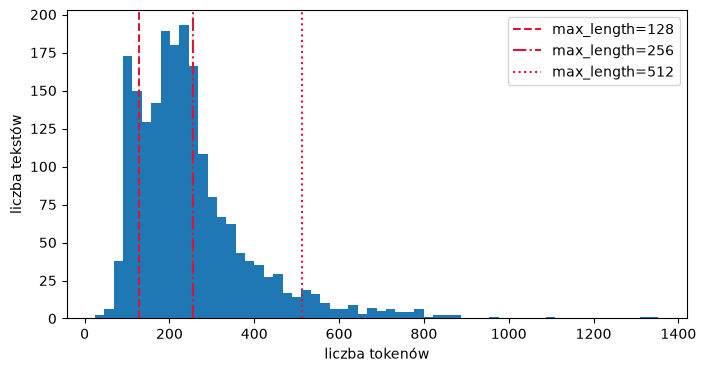

In [9]:
train_lens = np.array([
    len(ids) for ids in tokenizer(train_df["text"].tolist(), truncation=False)["input_ids"]
])

display(pd.Series({
    "mediana": np.median(train_lens),
    "p90": np.percentile(train_lens, 90),
    "p95": np.percentile(train_lens, 95),
    "maksimum": train_lens.max(),
    "% obciętych przy 128": 100 * (train_lens > 128).mean(),
}).round(1).to_frame("liczba tokenów"))

display(pd.DataFrame({
    "max_length": [128, 256, 384, 512],
    "% obciętych": [round(100 * (train_lens > L).mean(), 1) for L in [128, 256, 384, 512]],
}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_lens, bins=60)
for L, ls in [(128, "--"), (256, "-."), (512, ":")]:
    ax.axvline(L, color="crimson", linestyle=ls, label=f"max_length={L}")
ax.set_xlabel("liczba tokenów"); ax.set_ylabel("liczba tekstów"); ax.legend()
plt.show()

128 nie wydaje się dobrą wartością do dalszej części laboratorium. Mediana to 222 tokeny, p90 416, p95 524, a maksimum 1807. Przy 128 obcinane jest 84.3% tekstów, więc model w większości recenzji nie zobaczyłby podsumowania oceny. Wybieram MAX_LENGTH = 512, które obcina tylko koło 5.4% tekstów.

In [10]:
MAX_LENGTH = 512

# Zadanie 3: Co znajduje się w modelu?

Proszę wczytać bazowy enkoder przez `AutoModel` i odczytać z konfiguracji:

- rozmiar słownika;
- wymiar stanu ukrytego;
- liczbę warstw;
- liczbę głów uwagi;
- maksymalną długość sekwencji.

Następnie proszę samodzielnie policzyć:

- wszystkie parametry modelu;
- parametry trenowalne;
- przybliżony rozmiar samych wag w FP32 i FP16.

Proszę krótko wyjaśnić, dlaczego rzeczywiste zużycie pamięci podczas treningu jest większe niż rozmiar samych wag.


In [11]:
base_model = AutoModel.from_pretrained(MODEL_NAME)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1376.28it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [12]:
config = base_model.config

display(pd.Series({
    "rozmiar słownika": config.vocab_size,
    "wymiar stanu ukrytego": config.hidden_size,
    "liczba warstw": config.num_hidden_layers,
    "liczba głów uwagi": config.num_attention_heads,
    "maks. długość sekwencji": config.max_position_embeddings,
}).to_frame("wartość"))

,wartość
rozmiar słownika,119547
wymiar stanu ukrytego,768
liczba warstw,6
liczba głów uwagi,12
maks. długość sekwencji,512


In [13]:
total_params = sum(p.numel() for p in base_model.parameters())
trainable_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
embedding_params = base_model.embeddings.word_embeddings.weight.numel()

display(pd.Series({
    "wszystkie parametry": f"{total_params:,}",
    "parametry trenowalne": f"{trainable_params:,}",
    "w tym embeddingi słów": f"{embedding_params:,} ({100 * embedding_params / total_params:.1f}%)",
    "wagi FP32 (4 B/param)": f"{total_params * 4 / 2**20:.0f} MB",
    "wagi FP16 (2 B/param)": f"{total_params * 2 / 2**20:.0f} MB",
}).to_frame("wartość"))

,wartość
wszystkie parametry,"134,734,080"
parametry trenowalne,"134,734,080"
w tym embeddingi słów,"91,812,096 (68.1%)"
wagi FP32 (4 B/param),514 MB
wagi FP16 (2 B/param),257 MB


Podczas treningu oprócz wag w pamięci są gradienty (tyle samo co wagi), stan optymalizatora AdamW (dwie dodatkowe wartości na parametr) i aktywacje zapisane do backpropagation. Wagi, gradienty i AdamW to razem ok. 4× rozmiar wag, czyli ok. 2 GB w FP32. Aktywacje dochodzą do tego i rosną z batch size i długością sekwencji, więc przy MAX_LENGTH=512 będą dużo większe niż przy 128.

# Zadanie 4: Ręczne przejście w przód

Proszę wybrać jeden tekst i wykonać `tekst → tokenizator → tensory → AutoModel → last_hidden_state` bez użycia `pipeline()`.

Należy:

1. podać kształty tensorów wejściowych;
2. podać kształt `last_hidden_state`;
3. wyjaśnić znaczenie każdego wymiaru;
4. przypisać tokeny do odpowiadających im reprezentacji;
5. utworzyć jeden wektor dokumentu przez mean pooling z uwzględnieniem `attention_mask`.

Następnie proszę wczytać `AutoModelForSequenceClassification`, wykonać pojedynczą predykcję przed treningiem i:

- odczytać logity;
- zastosować softmax;
- sprawdzić, czy wartości po softmax sumują się do 1.

Proszę pamiętać, że wynik softmax nie jest automatycznie skalibrowaną miarą pewności modelu.

Na końcu proszę wyjaśnić, dlaczego predykcja z losowo zainicjalizowaną głową klasyfikacyjną nie ma jeszcze sensownej jakości.


In [14]:
text = "Hotel nawet czysty, obsługa bardzo miła, ale śniadania były co najwyżej przeciętne, a kawa zimna. Nie polecam."

inputs = tokenizer(text, return_tensors="pt")
print("input_ids:", tuple(inputs["input_ids"].shape))
print("attention_mask:", tuple(inputs["attention_mask"].shape))

base_model = base_model.to(DEVICE).eval()
inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

with torch.no_grad():
    outputs = base_model(**inputs)

hidden = outputs.last_hidden_state
print("last_hidden_state:", tuple(hidden.shape))

input_ids: (1, 40)
attention_mask: (1, 40)
last_hidden_state: (1, 40, 768)


In [15]:
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
display(pd.DataFrame({
    "pozycja": range(len(tokens)),
    "token": tokens,
    "wektor (pierwsze 5 z 768)": [np.round(v[:5].cpu().numpy(), 3) for v in hidden[0]],
}))

,pozycja,token,wektor (pierwsze 5 z 768)
0,0,[CLS],"[-0.118, -0.077, -0.128, 0.212, 0.063]"
1,1,Hotel,"[-0.184, -0.123, -0.147, 0.551, 0.12]"
2,2,nawet,"[0.024, -0.275, 0.012, 0.606, 0.113]"
3,3,czy,"[-0.24, 0.001, -0.15, 0.451, 0.218]"
4,4,##sty,"[-0.171, -0.361, -0.327, 0.546, 0.874]"
5,5,",","[-0.162, -0.216, -0.096, 0.373, 0.375]"
6,6,ob,"[-0.397, 0.087, 0.077, 0.493, 0.3]"
7,7,##s,"[-0.225, -0.423, 0.569, 0.458, 0.627]"
8,8,##ług,"[-0.575, -0.163, 0.624, 0.694, 0.278]"
9,9,##a,"[-0.075, -0.036, 0.833, 0.567, 0.087]"


In [16]:
mask = inputs["attention_mask"].unsqueeze(-1).float()
doc_vector = (hidden * mask).sum(dim=1) / mask.sum(dim=1)
print("wektor dokumentu:", tuple(doc_vector.shape))

cls_vector = hidden[:, 0]
print("cos(mean, [CLS]):", round(torch.nn.functional.cosine_similarity(doc_vector, cls_vector).item(), 3))

wektor dokumentu: (1, 768)
cos(mean, [CLS]): 0.23


In [17]:
label2id = {label: i for i, label in enumerate(CLASSES)}
id2label = {i: label for label, i in label2id.items()}

clf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASSES), label2id=label2id, id2label=id2label
).to(DEVICE).eval()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 697.83it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
with torch.no_grad():
    logits = clf_model(**inputs).logits

probs = torch.softmax(logits, dim=-1)
display(pd.DataFrame({
    "klasa": CLASSES,
    "logit": logits[0].cpu().numpy().round(4),
    "softmax": probs[0].cpu().numpy().round(4),
}))
print("suma softmax:", probs.sum().item())
print("predykcja:", id2label[probs.argmax(-1).item()])

print(clf_model.pre_classifier, clf_model.classifier)

,klasa,logit,softmax
0,amb,-0.0274,0.2398
1,minus,-0.0268,0.2399
2,plus,0.0331,0.2547
3,zero,0.0750,0.2656


suma softmax: 1.0
predykcja: zero
Linear(in_features=768, out_features=768, bias=True) Linear(in_features=768, out_features=4, bias=True)


Uwaga do zadań 3-4: Nazwy pól w konfiguracji DistilBERT różnią się od BERT-a (`dim`, `n_layers`, `n_heads`), ale działają też aliasy (`hidden_size`, `num_hidden_layers`, `num_attention_heads`).

Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę wyjaśnić, które to wagi i dlaczego jest to oczekiwane.

Którą pozycję z `last_hidden_state` wykorzystuje głowa klasyfikacyjna tego modelu i czym różni się to od mean poolingu?

Predykcja przed treningiem nie ma sensownej jakości, bo głowa klasyfikacyjna została dopiero co zainicjalizowana losowo. Jej wagi nie zawierają jeszcze żadnej informacji o tym, jak wektor [CLS] z enkodera przekłada się na klasy sentymentu amb, minus, plus i zero. Logity są więc przypadkowe, a po softmaxie prawdopodobieństwa klas niewiele się różnią (0,22–0,30). O wyniku - zero - zadecydował przypadek, a nie treść recenzji, która jest zdecydownie negatywna. Enkoder jest wstępnie wytrenowany, ale dopiero trening na danych PolEmo ustawi wagi głowy tak, by predykcje odzwierciedlały etykiety.

# Zadanie 5: Przygotowanie klasyfikatora

Proszę przygotować pełny pipeline treningowy dla klasyfikacji PolEmo 2.0.

Należy samodzielnie:

1. przygotować mapowania `label2id` i `id2label`;
2. utworzyć obiekty `Dataset` dla `train` i `validation`;
3. napisać funkcję tokenizującą batch;
4. użyć dynamicznego `DataCollatorWithPadding`;
5. zaimplementować `compute_metrics`;
6. przygotować `TrainingArguments`;
7. utworzyć `Trainer`.

Główną metryką jest `macro-F1`.

Konfiguracja domyślna (zmiana tylko z uzasadnieniem): 3 epoki, batch size 16, `weight_decay=0.01`, `warmup_ratio=0.1`, `MAX_LENGTH` z Zadania 2.

Proszę ustawić `report_to="none"` i `save_strategy="no"` (domyślnie `Trainer` zapisuje checkpointy po ok. 0,5 GB). Nazwy argumentów `TrainingArguments` i `Trainer` zmieniały się między wersjami `transformers` (m.in. `evaluation_strategy` → `eval_strategy`, `tokenizer` → `processing_class`), więc proszę zapisać `import transformers`.

Proszę zapisać użyte `MAX_LENGTH`, batch size, learning rate, liczbę epok, seed i urządzenie.

In [19]:
train_df["labels"] = train_df["target"].map(label2id)
val_df["labels"] = val_df["target"].map(label2id)

print(label2id)
print(train_df[["target", "labels"]].head())

{'amb': 0, 'minus': 1, 'plus': 2, 'zero': 3}
  target  labels
0    amb       0
1    amb       0
2    amb       0
3   plus       2
4   plus       2


In [20]:
train_ds = Dataset.from_pandas(train_df[["text", "labels"]])
val_ds = Dataset.from_pandas(val_df[["text", "labels"]])

In [21]:
def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

In [22]:
train_ds = train_ds.map(tokenize_batch, batched=True, remove_columns=["text"])
val_ds = val_ds.map(tokenize_batch, batched=True, remove_columns=["text"])

print(train_ds)

Map: 100%|██████████| 723/723 [00:00<00:00, 1928.20 examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})


In [23]:
data_collator = DataCollatorWithPadding(tokenizer)

In [24]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro")
    }

In [25]:
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
EPOCHS = 3

training_args = TrainingArguments(
    output_dir="tmp_trainer",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=0.1,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=RANDOM_STATE,
)

In [26]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASSES), label2id=label2id, id2label=id2label
).to(DEVICE)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 455.42it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [27]:
import transformers

config = pd.Series({
    "transformers": transformers.__version__,
    "MAX_LENGTH": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "seed": RANDOM_STATE,
    "device": DEVICE,
}).to_frame("wartość")
display(config)

,wartość
transformers,5.22.1
MAX_LENGTH,512
batch_size,16
learning_rate,0.00002
epochs,3
seed,42
device,cpu


# Zadanie 6: Zamrożony enkoder

Proszę załadować model klasyfikacyjny i zamrozić cały enkoder (`model.base_model`). Trenowana ma być wyłącznie głowa klasyfikacyjna (w DistilBERT: `pre_classifier` i `classifier`).

Learning rate dla tego wariantu proszę dobrać osobno (typowo ok. `1e-3`; wartość rzędu `2e-5` prawie nie uczy samej głowy w trzech epokach). Liczba epok i pozostałe warunki są takie same jak w zadaniu 5.

Proszę:

1. policzyć liczbę wszystkich parametrów;
2. policzyć liczbę parametrów trenowalnych;
3. podać procent parametrów trenowalnych;
4. wytrenować model;
5. zmierzyć czas treningu;
6. obliczyć accuracy i macro-F1 na zbiorze walidacyjnym.

Przed treningiem proszę zapisać hipotezę dotyczącą oczekiwanej jakości tego wariantu.

In [28]:
fr_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASSES), label2id=label2id, id2label=id2label
).to(DEVICE)

for param in fr_model.base_model.parameters():
    param.requires_grad = False

fr_training_args = TrainingArguments(
    output_dir="tmp_trainer",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    learning_rate=1e-3,
    weight_decay=0.01,
    warmup_steps=0.1,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=RANDOM_STATE,
)

fr_trainer = Trainer(
    model=fr_model,
    args=fr_training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 463.82it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
fr_total_params = sum(p.numel() for p in fr_model.parameters())
fr_trainable_params = sum(p.numel() for p in fr_model.parameters() if p.requires_grad)
fr_trainable_fraction = fr_trainable_params / fr_total_params

print(f"Liczba wszystkich parametrów: {fr_total_params}")
print(f"Liczba trenowalnych parametrów: {fr_trainable_params}")
print(f"Procent trenowalnych parametrów: {(fr_trainable_fraction*100):.4f}%")

Liczba wszystkich parametrów: 135327748
Liczba trenowalnych parametrów: 593668
Procent trenowalnych parametrów: 0.4387%


In [ ]:
PRED_REPEATS = 10

start = time.perf_counter()
fr_trainer.train()
fr_train_s = time.perf_counter() - start
print(f"Czas treningu: {fr_train_s:.1f} s")

fr_metrics = fr_trainer.evaluate()
print(fr_metrics)

c:\Users\zsuet\Desktop\nlp\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [ ]:
fr_pred_s = 0
for _ in range(PRED_REPEATS):
    start = time.perf_counter()
    fr_pred = fr_trainer.predict(val_ds)
    fr_pred_s += time.perf_counter() - start
fr_pred_avg_s = fr_pred_s / PRED_REPEATS 

fr_val_preds = fr_pred.predictions.argmax(axis=-1)

fr_ms_doc = fr_pred_avg_s / len(val_ds) * 1000
fr_f1, fr_lo, fr_hi = bootstrap_ci(val_df["label"], fr_val_preds, macro_f1)
fr_acc = accuracy_score(val_df["label"], fr_val_preds)

# Zadanie 7: Pełne dostrajanie i porównanie na walidacji

Proszę załadować świeżą kopię tego samego checkpointu i przeprowadzić pełne dostrajanie modelu.

Warunki: ten sam podział danych, to samo `MAX_LENGTH`, ten sam sposób ewaluacji i ta sama liczba epok co w Zadaniu 5. Learning rate dobieramy osobno do wariantu (pełne dostrajanie: typowo `2e-5`–`5e-5`).

Dla wariantu dostrojonego proszę zmierzyć: liczbę parametrów trenowalnych, czas treningu, accuracy, macro-F1 i średni czas inferencji na dokument (ta sama maszyna, podany batch size).

| model | trainable params | train_s | ms/doc | accuracy | macro-F1 | macro-F1 CI95 |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF + Linear SVM | -- | | | | | |
| frozen transformer | | | | | | |
| fine-tuned transformer | | | | | | |

Przedział ufności liczymy funkcją `bootstrap_ci` z Lab 2. Predykcje walidacyjne obu transformerów proszę zapisać (będą potrzebne w Zadaniach 8 i 10).

Opcjonalnie: proszę powtórzyć dostrajanie dla drugiego seeda. Dostrajanie ma wyraźną wariancję między seedami, więc różnic rzędu kilku dziesiątych punktu macro-F1 nie należy traktować jako przewagi.

In [ ]:
ft_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASSES), label2id=label2id, id2label=id2label
).to(DEVICE)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 831.35it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
learning_rate = 2e-5

ft_training_args = TrainingArguments(
    output_dir="tmp_trainer",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    learning_rate=learning_rate,
    weight_decay=0.01,
    warmup_steps=0.1,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=RANDOM_STATE,
)

ft_trainer = Trainer(
    model=ft_model,
    args=ft_training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

In [ ]:
ft_trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)

print(f"Liczba trenowalnych parametrów: {ft_trainable_params}")

Liczba trenowalnych parametrów: 135327748


In [ ]:
start = time.perf_counter()
ft_trainer.train()
ft_train_s = time.perf_counter() - start
print(f"Czas treningu: {ft_train_s:.1f} s")

ft_metrics = ft_trainer.evaluate()
print(ft_metrics)

NameError: name 'time' is not defined

In [ ]:
ft_pred_s = 0
for _ in range(PRED_REPEATS):
    start = time.perf_counter()
    ft_pred = ft_trainer.predict(val_ds)
    ft_pred_s += time.perf_counter() - start
ft_pred_avg_s = ft_pred_s / PRED_REPEATS 

ft_val_preds = ft_pred.predictions.argmax(axis=-1)

ft_ms_doc = ft_pred_avg_s / len(val_ds) * 1000
ft_f1, ft_lo, ft_hi = bootstrap_ci(val_df["label"], ft_val_preds, macro_f1)
ft_acc = accuracy_score(val_df["label"], ft_val_preds)

In [ ]:
import joblib
from sklearn.base import clone

svm_model = joblib.load(ARTIFACTS / "word_svc.joblib")
y_val_str = val_df["target"]

times = []
for _ in range(PRED_REPEATS):
    start = time.perf_counter()
    svm_val_preds = svm_model.predict(val_df["text_norm"])
    times.append(time.perf_counter() - start)
svm_ms_doc = float(np.median(times)) / len(val_df) * 1000

full_train = data[data["split"] == "train"]
start = time.perf_counter()
clone(svm_model).fit(full_train["text_norm"], full_train["target"])
svm_train_s = time.perf_counter() - start

svm_acc = accuracy_score(y_val_str, svm_val_preds)
svm_f1, svm_lo, svm_hi = bootstrap_ci(y_val_str, svm_val_preds, macro_f1)

svm_val_ids = pd.Series(svm_val_preds).map(label2id).to_numpy()

In [ ]:
results = []

results.append({
    "model": MODEL_NAME + " (frozen transformer)",
    "trainable params": fr_trainable_params,
    "train_s": round(fr_train_s, 2),
    "ms/doc": round(fr_ms_doc, 4),
    "accuracy": round(fr_acc, 4),
    "macro-F1": round(fr_f1, 4),
    "macro-F1 CI95": f"[{fr_lo:.3f}, {fr_hi:.3f}]",
})

results.append({
    "model": MODEL_NAME + " (fine-tuned transformer)",
    "trainable params": ft_trainable_params,
    "train_s": round(ft_train_s, 2),
    "ms/doc": round(ft_ms_doc, 4),
    "accuracy": round(ft_acc, 4),
    "macro-F1": round(ft_f1, 4),
    "macro-F1 CI95": f"[{ft_lo:.3f}, {ft_hi:.3f}]",
})

results.append({
    "model": "TF-IDF + Linear SVM",
    "trainable params": "--",
    "train_s": round(svm_train_s, 2),
    "ms/doc": round(svm_ms_doc, 4),
    "accuracy": round(svm_acc, 4),
    "macro-F1": round(svm_f1, 4),
    "macro-F1 CI95": f"[{svm_lo:.3f}, {svm_hi:.3f}]",
})

results_df = pd.DataFrame(results)
display(results_df)

# (opcjonalnie) Zadanie 8: Model polski czy wielojęzyczny?

Dotychczas używaliśmy `distilbert-base-multilingual-cased` (6 warstw, słownik wielojęzyczny). Sprawdzimy, czy model wstępnie wytrenowany na polskich korpusach, `allegro/herbert-base-cased` (BERT, 12 warstw, słownik 50 tys. tokenów), daje przewagę i za jaką cenę.

## Część A: tokenizacja (bez treningu)

Proszę wczytać oba tokenizatory (HerBERT: `AutoTokenizer.from_pretrained(MODEL_PL)`) i dla 500 losowych dokumentów z `train_df` policzyć funkcją `token_stats`: medianę i p90 liczby tokenów, procent tekstów obciętych przy `MAX_LENGTH` oraz liczbę tokenów na słowo.

Następnie proszę porównać podział przykładów z Zadania 1 (także form z odciętą końcówką osobową, np. `Był em`, `miała m`) i zapisać, które słowa dzielą się inaczej.

## Część B: dostrajanie

Proszę dostroić HerBERT-a w tych samych warunkach co dostrojony DistilBERT z Zadania 7: te same `MAX_LENGTH`, liczba epok, batch size, seed i próbka danych, learning rate z tego samego przedziału. Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę zapisać, które warstwy są nowe.

## Część C: porównanie

Proszę rozszerzyć tabelę z Zadania 7 o wiersz `fine-tuned HerBERT` (trainable params, train_s, ms/doc, accuracy, macro-F1, CI95) oraz policzyć różnicę macro-F1 (HerBERT − DistilBERT) z przedziałem ufności funkcją `paired_bootstrap_diff` na tych samych przykładach walidacyjnych.

Pytania:

1. Który model ma więcej parametrów, a który jest wolniejszy? Dlaczego liczba parametrów nie wystarcza do oszacowania kosztu obliczeń?
2. Czy różnica jakości jest istotna w świetle przedziału ufności?
3. Czy tokenizatory inaczej dzielą polskie formy (Część A)? Czy na podstawie tego eksperymentu można stwierdzić, że to wyjaśnia różnicę jakości?

In [ ]:
# Część A: porównanie tokenizatorów (token_stats)
# Część B: dostrojenie HerBERT-a (zapisać predykcje walidacyjne)
# Część C: tabela i paired_bootstrap_diff

# Zadanie 9*: Wybór finalisty i ostateczny test

Na podstawie wyłącznie wyników walidacyjnych (Zadania 6-8) proszę wybrać jeden wariant do końcowej oceny. Jeśli różnica między kandydatami mieści się w przedziale ufności, proszę to zaznaczyć i uzasadnić wybór kosztem.

Następnie:

1. proszę połączyć `train + validation`;
2. wytrenować wybrany wariant od początku (te same hiperparametry i liczba epok);
3. wykonać jedną ocenę na zbiorze testowym.

Proszę zapisać accuracy, macro-F1, F1 dla każdej klasy, macierz pomyłek i czas inferencji, a wynik porównać z wynikiem testowym `TF-IDF + Linear SVM` z Lab 2 (ten sam zbiór testowy).

Po obejrzeniu wyniku testowego konfiguracja nie może być już zmieniana.

Uwaga: model finalny widział `validation`, więc analiza błędów (zadanie 10) dotyczy modelu wytrenowanego wyłącznie na `train`.

In [ ]:
# Proszę wybrać finalistę na validation i wykonać jednorazowy finalny test.

# Zadanie 10*: Analiza błędnych predykcji

Dla najlepszego transformera wytrenowanego wyłącznie na `train` (nie dla modelu finalnego z zadania 9) proszę wybrać dokładnie 12 błędnych predykcji ze zbioru walidacyjnego (wylosowanych z `random_state=RANDOM_STATE`).

Każdy przypadek proszę przypisać do krótkiej kategorii, np. `AMBIGUOUS_GOLD`, `MIXED_SENTIMENT`, `NEGATION`, `IRONY_SARCASM`, `LONG_CONTEXT`, `VERY_SHORT`, `LEXICAL_TRAP`, `TRUNCATION`, `NON_REVIEW`, `PRETOKENIZATION`, `OTHER`.

Tabela powinna zawierać:

| nr | tekst | gold | predykcja | typ błędu | komentarz |
|---:|---|---|---|---|---|

Proszę dodatkowo zaznaczyć, jeśli w labie stworzyli Państwo takie check, czy TF-IDF + Linear SVM (predykcje z labu 2) popełnił ten sam błąd.

Nie należy jeszcze proponować rozwiązania każdego pojedynczego błędu. Najpierw proszę wskazać powtarzające się wzorce.

In [ ]:
# Proszę przygotować analizę dokładnie 12 błędnych predykcji.

# Zadanie 11*: Interpretacja, decyzja projektowa i wnioski

To zadanie nie wymaga nowej implementacji.

Na podstawie wykonanych eksperymentów proszę odpowiedzieć:

1. Co zmieniło pełne dostrajanie względem zamrożonego enkodera?
2. Czy wzrost jakości był proporcjonalny do wzrostu kosztu treningu?
3. Jakie typy błędów dominują w analizie 12 przypadków i czy któryś z nich prawdopodobnie nie ustąpi po zwiększeniu modelu?
4. Czy wynik tego laboratorium pozwala stwierdzić, że transformer jest ogólnie lepszy od `TF-IDF + Linear SVM`? Dlaczego?
5. (jeśli wykonano Zadanie 8) Czy model polski ma przewagę nad wielojęzycznym i czy ta przewaga uzasadnia koszt?

Następnie proszę wybrać rozwiązanie dla dwóch scenariuszy: **A** (najważniejsza jest jakość), **B** (najważniejsze są niski koszt, szybkie uczenie i szybka inferencja). Dla każdego proszę podać: wybrany model, wynik jakościowy, koszt do zaakceptowania i najważniejsze ograniczenie.

Na końcu jednym akapitem: **Kiedy dodatkowa złożoność transformera jest uzasadniona, a kiedy mocny model klasyczny pozostaje lepszą decyzją inżynierską?**ę

Proszę przygotować wnioski dotyczące zadania (5-8 krótkich wniosków opartych na wynikach, obejmujących tokenizację, MAX_LENGTH, frozen vs fine-tuning, SVM vs transformer, koszt i błędy).

# Karta modelu

Proszę utworzyć:

```text
artifacts/transformer_model_card.md
```

Karta powinna zawierać:

## Model
- checkpoint;
- typ architektury;
- (opcjonalnie) checkpoint modelu polskiego i liczba parametrów;
- liczba parametrów.

## Tokenizator
- checkpoint;
- `MAX_LENGTH`;
- decyzje z zad 2
- procent tekstów obciętych przy `MAX_LENGTH`;
- (jeśli wykonano Zadanie 8) porównanie z tokenizatorem HerBERT-a (tokeny na słowo);
- sposób paddingu i obcinania.

## Zadanie
- przewidywane klasy;
- mapowanie `label2id` i `id2label`.

## Dane
- liczebność `train`, `validation`, `test`;
- ewentualne ograniczenie liczby przykładów z powodów sprzętowych.

## Trening
- batch size;
- learning rate;
- liczba epok;
- wariant: frozen / fine-tuned;
- liczba parametrów trenowalnych.

## Wyniki
- `TF-IDF + Linear SVM`;
- frozen transformer;
- fine-tuned transformer;
- fine-tuned HerBERT (jeśli wykonano);
- finalny wynik testowy.

## Koszt
- urządzenie;
- czas treningu;
- ms/dokument.

## Błędy
- dominujące typy błędów z analizy 12 przypadków.

## Zastosowanie
- kiedy użycie transformera jest uzasadnione;
- kiedy prostszy baseline może być lepszym wyborem.

## Ograniczenia
- ograniczenia danych;
- ograniczenia eksperymentu;
- czego wyniki tego laboratorium nie pozwalają stwierdzić.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] audyt tokenizacji dla co najmniej 8 przykładów;
- [ ] analizę `input_ids`, `attention_mask` i porównanie sposobów paddingu;
- [ ] analizę długości tokenowych i decyzję dotyczącą `MAX_LENGTH`;
- [ ] odczyt parametrów architektury, liczbę parametrów i koszt pamięci wag;
- [ ] ręczne przejście w przód bez `pipeline()` oraz mean pooling;
- [ ] analizę logitów i wyniku softmax;
- [ ] samodzielnie przygotowany pipeline treningowy;
- [ ] trening przy zamrożonym enkoderze (z osobno dobranym learning rate);
- [ ] pełne dostrajanie;
- [ ] tabelę porównawczą na validation z przedziałami ufności;
- [ ] porównanie z HerBERT-em, w tym paired bootstrap *(opcjonalnie)*;
- [ ] wybór konfiguracji na validation i jednorazową ocenę na test (z porównaniem do baseline'u z Lab 2);
- [ ] tabelę dokładnie 12 błędnych predykcji (model trenowany tylko na `train`);
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 11);
- [ ] plik `artifacts/transformer_model_card.md`.